# Shoplifting VideoMAE Small — No Validation
Uses **all 537 original training videos** and keeps the **95 original test videos** strictly out of training. Fixed schedule: 2 head-only epochs, then 6 fine-tuning epochs (last two Transformer blocks). No validation, early stopping, or best-epoch selection. **No crop**: full-frame 224×224 resize and temporally consistent flip/color jitter.

**Caution:** The existing test split was already inspected in earlier experiments; its score is an internal comparison, not a fresh generalization estimate. Removing validation prevents monitoring overfitting and does not guarantee higher accuracy. Original notebook and model outputs remain unchanged.


In [1]:
%pip -q install "transformers>=4.45,<5" accelerate

from pathlib import Path
import pandas as pd
import torch

from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = Path(
    "/content/drive/MyDrive/Cellula/"
    "Shoplifting-Detection/DataSet"
)

SPLIT_PATH = (
    DATA_ROOT
    / "shoplifting_independent_v6_no_attention"
    / "video_split.csv"
)

assert SPLIT_PATH.is_file(), (
    f"Existing split not found: {SPLIT_PATH}"
)

manifest = pd.read_csv(SPLIT_PATH)

assert len(manifest) == 632
assert manifest["sha256"].is_unique
assert set(manifest["split"]) == {"train", "test"}

manifest["video_path"] = manifest["relative_path"].apply(
    lambda p: str(DATA_ROOT / p)
)

assert all(
    Path(p).is_file()
    for p in manifest["video_path"]
)

print(pd.crosstab(
    manifest["split"],
    manifest["class_name"]
))

print("\nVideos with fewer than 16 sampled frames:")
print((manifest["sampled_frames"] < 16).sum())

print("\nVideos with 16 or more sampled frames:")
print((manifest["sampled_frames"] >= 16).sum())

print("\nDevice:", "CUDA" if torch.cuda.is_available() else "CPU")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Mounted at /content/drive
class_name  Normal  Shoplifting
split                          
test            47           48
train          263          274

Videos with fewer than 16 sampled frames:
462

Videos with 16 or more sampled frames:
170

Device: CUDA


In [2]:
from transformers import (
    VideoMAEImageProcessor,
    VideoMAEForVideoClassification
)

MODEL_ID = "MCG-NJU/videomae-small-finetuned-kinetics"

processor = VideoMAEImageProcessor.from_pretrained(
    MODEL_ID
)

model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
    id2label={0: "Normal", 1: "Shoplifting"},
    label2id={"Normal": 0, "Shoplifting": 1},
    ignore_mismatched_sizes=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Model:", MODEL_ID)
print("Input frames:", model.config.num_frames)
print("Image size:", model.config.image_size)
print("Classifier:", model.classifier)
print("Processor mean:", processor.image_mean)
print("Processor std:", processor.image_std)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# Sanity check with synthetic video input
x = torch.zeros(
    1,
    model.config.num_frames,
    3,
    model.config.image_size,
    model.config.image_size,
    device=device
)

with torch.inference_mode():
    y = model(pixel_values=x).logits

assert y.shape == (1, 2)

print("Output shape:", tuple(y.shape))
print("Model loading and forward pass: PASS")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Some weights of VideoMAEForVideoClassification were not initialized from the model checkpoint at MCG-NJU/videomae-small-finetuned-kinetics and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([400, 384]) in the checkpoint and torch.Size([2, 384]) in the model instantiated
- classifier.bias: found shape torch.Size([400]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: MCG-NJU/videomae-small-finetuned-kinetics
Input frames: 16
Image size: 224
Classifier: Linear(in_features=384, out_features=2, bias=True)
Processor mean: [0.485, 0.456, 0.406]
Processor std: [0.229, 0.224, 0.225]
Parameters: 21880706
Output shape: (1, 2)
Model loading and forward pass: PASS


In [3]:
# 3 — Configuration: ALL 537 training videos, NO validation
import random, time, json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Separate output; never overwrite the earlier experiment.
OUT = DATA_ROOT / 'shoplifting_pretrained_videomae_small_no_validation'
OUT.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path('/content/videomae_cache_16f_224')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

NUM_FRAMES = int(model.config.num_frames)
IMAGE_SIZE = int(model.config.image_size)
assert (NUM_FRAMES, IMAGE_SIZE) == (16, 224)
FLIP_PROB, COLOR_JITTER = 0.5, 0.15
MEAN = np.asarray(processor.image_mean, dtype=np.float32).reshape(1, 1, 1, 3)
STD = np.asarray(processor.image_std, dtype=np.float32).reshape(1, 1, 1, 3)

train_rows = manifest.loc[manifest.split == 'train'].reset_index(drop=True)
test_rows = manifest.loc[manifest.split == 'test'].reset_index(drop=True)
assert len(train_rows) == 537 and len(test_rows) == 95
assert set(train_rows.sha256).isdisjoint(set(test_rows.sha256))
assert set(train_rows.label) == {0, 1} and set(test_rows.label) == {0, 1}

print('Train:', len(train_rows), train_rows.label.value_counts().to_dict())
print('Test:', len(test_rows), test_rows.label.value_counts().to_dict())
print('Validation: DISABLED')
print('Input:', NUM_FRAMES, 'frames at', IMAGE_SIZE, 'px')
print('Crop: NONE (manual full-frame resize)')
print('Device:', device)
print('Note: the 95-video test was inspected in earlier experiments; it is not an untouched benchmark.')

Train: 537 {1: 274, 0: 263}
Test: 95 {1: 48, 0: 47}
Validation: DISABLED
Input: 16 frames at 224 px
Crop: NONE (manual full-frame resize)
Device: cuda
Note: the 95-video test was inspected in earlier experiments; it is not an untouched benchmark.


In [4]:
# 4 — 1 FPS sampling + exactly 16 RGB frames
# NO CENTER CROP / RANDOM CROP / RESIZED CROP

def extract_video_frames(path):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    try:
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if not np.isfinite(fps) or fps <= 0 or total <= 0:
            raise ValueError(f"Invalid video metadata: {path}")

        # Original pipeline: sample at 1 FPS.
        seconds = np.arange(0, total / fps, 1.0)
        sample_ids = np.rint(seconds * fps).astype(np.int64)
        sample_ids = np.unique(np.clip(sample_ids, 0, total - 1))

        if len(sample_ids) == 0:
            raise RuntimeError(f"No sampled frames: {path}")

        # Uniformly select 16 positions from 1 FPS samples.
        # Short videos repeat positions; no spatial crop.
        positions = np.rint(
            np.linspace(0, len(sample_ids) - 1, NUM_FRAMES)
        ).astype(int)

        chosen_ids = sample_ids[positions]

        frames = []
        for idx in chosen_ids:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, bgr = cap.read()

            if not ok or bgr is None:
                raise RuntimeError(
                    f"Failed decoding frame {idx}: {path}"
                )

            # Resize entire frame. Nothing is cropped.
            bgr = cv2.resize(
                bgr,
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=cv2.INTER_AREA
            )

            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            frames.append(rgb)

        return np.stack(frames).astype(np.uint8)

    finally:
        cap.release()


def get_cached_clip(row):
    cache_path = CACHE_DIR / (
        f"{row['sha256']}_{NUM_FRAMES}f_{IMAGE_SIZE}.npy"
    )

    if not cache_path.exists():
        frames = extract_video_frames(row["video_path"])
        np.save(cache_path, frames)

    frames = np.load(cache_path, allow_pickle=False)

    assert frames.shape == (
        NUM_FRAMES, IMAGE_SIZE, IMAGE_SIZE, 3
    )
    assert frames.dtype == np.uint8

    return frames


# Cache ALL training videos; do NOT pre-cache test during training.
precache_rows = train_rows

for row in tqdm(
    precache_rows.to_dict("records"),
    desc="Preparing VideoMAE frame cache"
):
    get_cached_clip(row)

print("Full training frame cache ready.")
print("No crop applied.")

Preparing VideoMAE frame cache:   0%|          | 0/537 [00:00<?, ?it/s]

Full training frame cache ready.
No crop applied.


Sample tensor shape: torch.Size([16, 3, 224, 224])
Sample label: 0


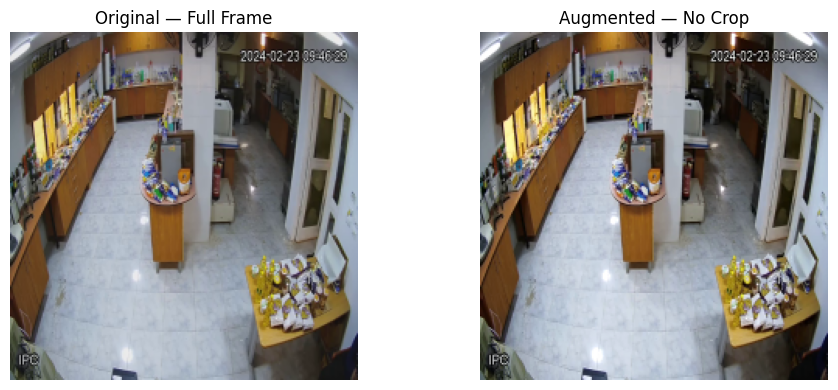

In [5]:
# 5 — Temporally consistent augmentation and dataset

def augment_clip(frames):
    flip = random.random() < FLIP_PROB

    brightness = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )
    contrast = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )
    saturation = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )

    if flip:
        frames = frames[:, :, ::-1, :]

    result = []

    for frame in frames:
        image = Image.fromarray(
            np.ascontiguousarray(frame)
        )

        image = ImageEnhance.Brightness(
            image
        ).enhance(brightness)

        image = ImageEnhance.Contrast(
            image
        ).enhance(contrast)

        image = ImageEnhance.Color(
            image
        ).enhance(saturation)

        result.append(np.asarray(image, dtype=np.uint8))

    return np.stack(result)


def frames_to_tensor(frames):
    # Model-specific normalization; not V6's [-1, 1].
    x = frames.astype(np.float32) / 255.0
    x = (x - MEAN) / STD

    # (T, H, W, C) -> (T, C, H, W)
    x = np.transpose(x, (0, 3, 1, 2)).copy()

    return torch.from_numpy(x)


class ShopliftingVideoMAEDataset(Dataset):
    def __init__(self, rows, training=False):
        self.rows = rows.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        frames = get_cached_clip(row)

        if self.training:
            frames = augment_clip(frames)

        tensor = frames_to_tensor(frames)
        label = int(row["label"])

        return tensor, label


BATCH_SIZE = 2 if device.type == "cuda" else 1
GRAD_ACCUM = 4
USE_AMP = device.type == "cuda"

train_ds = ShopliftingVideoMAEDataset(
    train_rows, training=True
)
test_ds = ShopliftingVideoMAEDataset(
    test_rows, training=False
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0,
    pin_memory=USE_AMP
)

test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0,
    pin_memory=USE_AMP
)

x, y = train_ds[0]

assert x.shape == (
    NUM_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE
)

print("Sample tensor shape:", x.shape)
print("Sample label:", y)

# Compare original resized frame against augmented frame.
example = get_cached_clip(train_rows.iloc[0])
augmented = augment_clip(example)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(example[0])
axes[0].set_title("Original — Full Frame")
axes[1].imshow(augmented[0])
axes[1].set_title("Augmented — No Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Horizontal Flip: PASS


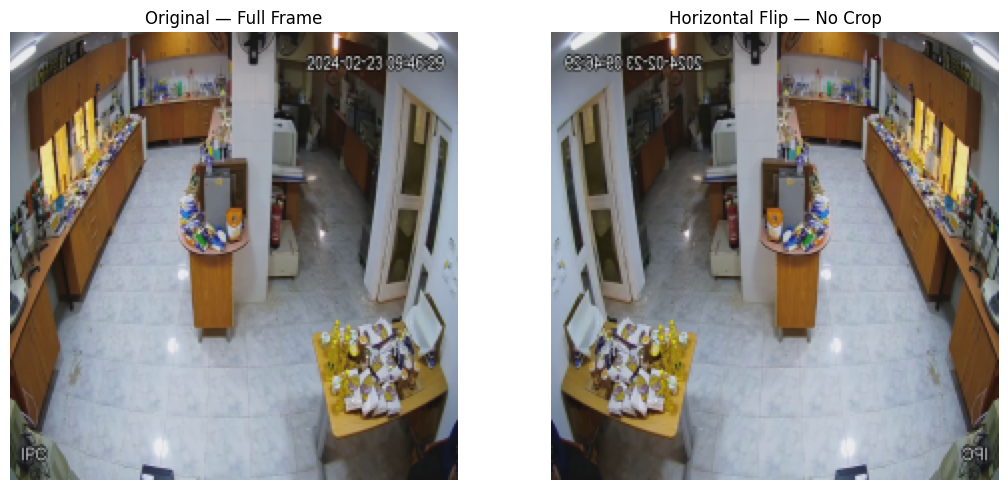

In [6]:
# Visual verification: FORCE horizontal flip for demonstration
# This does NOT change the training augmentation probability.

example = get_cached_clip(train_rows.iloc[0])

# Flip all frames horizontally (no crop)
flipped = example[:, :, ::-1, :].copy()

# Verify correct flipping
assert np.array_equal(flipped[0], example[0][:, ::-1, :])
print("Horizontal Flip: PASS")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(example[0])
axes[0].set_title("Original — Full Frame")

axes[1].imshow(flipped[0])
axes[1].set_title("Horizontal Flip — No Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# 6 — Fixed-epoch training on ALL 537 training clips; NO validation.
# Stage A: train classification head for 2 epochs.
# Stage B: fine-tune last two transformer blocks for 6 epochs.
# No checkpoint selection on test data, no early stopping.

HEAD_EPOCHS = 2
FINETUNE_EPOCHS = 6
HEAD_PATH = OUT / 'head_after_2_epochs.pt'
FINAL_PATH = OUT / 'final_finetuned_after_6_epochs.pt'
HISTORY_PATH = OUT / 'training_history.csv'

criterion = nn.CrossEntropyLoss()
history = []


def save_checkpoint(path, stage, epoch):
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if not all(torch.isfinite(v).all().item() for v in state.values() if torch.is_floating_point(v)):
        raise RuntimeError('Non-finite weight; refusing to save checkpoint')
    torch.save({
        'model': state, 'stage': stage, 'epoch': epoch,
        'model_id': MODEL_ID, 'labels': {0: 'Normal', 1: 'Shoplifting'},
        'frames': NUM_FRAMES, 'size': IMAGE_SIZE,
        'crop': False, 'sampling': '1 FPS then uniform 16 frames',
        'selection': 'final_epoch_fixed_in_advance_no_validation',
        'train_videos': len(train_rows),
    }, path)


def train_epoch(stage, optimizer, scaler):
    model.train()
    if stage == 'head':
        # The frozen feature extractor is held in eval mode.
        model.videomae.eval()
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer.zero_grad(set_to_none=True)
    n_batches = len(train_loader)
    total_loss = 0.0
    gold, pred = [], []
    for step, (clips, labels) in enumerate(tqdm(train_loader, leave=False), start=1):
        clips = clips.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        group_start = ((step - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(GRAD_ACCUM, n_batches - group_start)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(pixel_values=clips).logits
            loss = criterion(logits, labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError(f'Non-finite training loss on step {step}')
        scaler.scale(loss / group_size).backward()
        if step % GRAD_ACCUM == 0 or step == n_batches:
            scaler.unscale_(optimizer)
            norm = nn.utils.clip_grad_norm_(trainable, 1.0)
            if not torch.isfinite(norm).item():
                if not USE_AMP:
                    raise RuntimeError(f'Non-finite gradient at step {step}')
                # With CUDA AMP, GradScaler detects non-finite gradients
                # and safely skips that optimizer update.
                print(f'AMP overflow at step {step}; optimizer update skipped')
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        total_loss += float(loss.item()) * len(labels)
        gold.extend(labels.detach().cpu().tolist())
        pred.extend(logits.detach().argmax(1).cpu().tolist())
    return {
        'train_loss': total_loss / len(train_ds),
        'train_accuracy': accuracy_score(gold, pred),
        'train_f1_macro': f1_score(gold, pred, average='macro', zero_division=0),
    }


def run_fixed_stage(stage, epochs, optimizer, target):
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        result = train_epoch(stage, optimizer, scaler)
        result.update(stage=stage, epoch=epoch, seconds=time.perf_counter()-start)
        history.append(result)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        print(f'{stage} {epoch:02}/{epochs} | '
              f'Train loss {result["train_loss"]:.4f} | '
              f'Train F1 {result["train_f1_macro"]:.4f} | '
              f'Time {result["seconds"]:.1f}s')
    save_checkpoint(target, stage, epochs)  # Fixed final epoch, not best validation.
    print('Saved:', target)

# Stage A — classifier head
model.requires_grad_(False)
model.classifier.requires_grad_(True)
if getattr(model, 'fc_norm', None) is not None:
    model.fc_norm.requires_grad_(True)
head_optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=3e-4, weight_decay=0.01)
run_fixed_stage('head', HEAD_EPOCHS, head_optimizer, HEAD_PATH)
del head_optimizer

# Stage B — last 2 transformer blocks + classifier
model.requires_grad_(False)
last_blocks = model.videomae.encoder.layer[-2:]
for block in last_blocks:
    block.requires_grad_(True)
model.classifier.requires_grad_(True)
if getattr(model, 'fc_norm', None) is not None:
    model.fc_norm.requires_grad_(True)
encoder_params = [p for block in last_blocks for p in block.parameters() if p.requires_grad]
head_params = [p for p in model.classifier.parameters() if p.requires_grad]
if getattr(model, 'fc_norm', None) is not None:
    head_params.extend(model.fc_norm.parameters())
finetune_optimizer = torch.optim.AdamW(
    [{'params': encoder_params, 'lr': 1e-5},
     {'params': head_params, 'lr': 1e-4}], weight_decay=0.01)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
run_fixed_stage('finetune', FINETUNE_EPOCHS, finetune_optimizer, FINAL_PATH)
del finetune_optimizer

print('No validation has been used. TEST remains outside the training loop.')

  0%|          | 0/269 [00:00<?, ?it/s]

AMP overflow at step 269; optimizer update skipped
head 01/2 | Train loss 0.6845 | Train F1 0.5706 | Time 43.8s


  0%|          | 0/269 [00:00<?, ?it/s]

head 02/2 | Train loss 0.6596 | Train F1 0.6666 | Time 41.5s
Saved: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_pretrained_videomae_small_no_validation/head_after_2_epochs.pt
Trainable parameters: 3549698


  0%|          | 0/269 [00:00<?, ?it/s]

...

finetune 04/6 | Train loss 0.4460 | Train F1 0.8752 | Time 41.2s


  0%|          | 0/269 [00:00<?, ?it/s]

finetune 05/6 | Train loss 0.3512 | Train F1 0.8789 | Time 41.5s


  0%|          | 0/269 [00:00<?, ?it/s]

finetune 06/6 | Train loss 0.2951 | Train F1 0.8956 | Time 41.4s
Saved: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_pretrained_videomae_small_no_validation/final_finetuned_after_6_epochs.pt
No validation has been used. TEST remains outside the training loop.


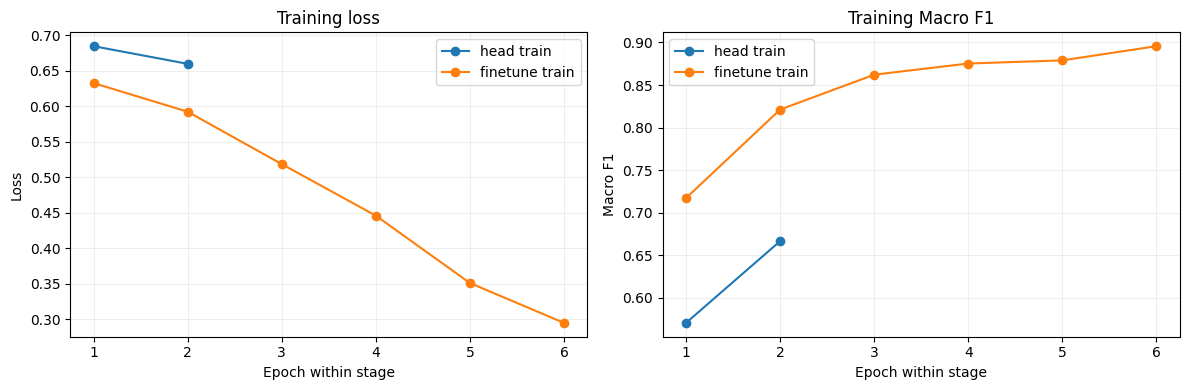

Saved: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_pretrained_videomae_small_no_validation/training_curves.png
Training curves alone cannot determine which epoch generalizes best.


In [8]:
# 7 — Train-only learning curves (no validation or test curves)
results = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stage, group in results.groupby('stage', sort=False):
    xs = np.arange(1, len(group)+1)
    axes[0].plot(xs, group.train_loss, marker='o', label=f'{stage} train')
    axes[1].plot(xs, group.train_f1_macro, marker='o', label=f'{stage} train')
axes[0].set(xlabel='Epoch within stage', ylabel='Loss', title='Training loss')
axes[1].set(xlabel='Epoch within stage', ylabel='Macro F1', title='Training Macro F1')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout()
plot_path = OUT / 'training_curves.png'
plt.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print('Saved:', plot_path)
print('Training curves alone cannot determine which epoch generalizes best.')

Final Test:   0%|          | 0/48 [00:00<?, ?it/s]


VideoMAE Small — Final Test Metrics
{
  "n_test": 95,
  "accuracy": 0.9157894736842105,
  "precision_macro": 0.9190518783542039,
  "recall_macro": 0.9153368794326242,
  "f1_macro": 0.9155555555555556,
  "shoplifting_recall": 0.9583333333333334
}

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.87      0.91        47
 Shoplifting       0.88      0.96      0.92        48

    accuracy                           0.92        95
   macro avg       0.92      0.92      0.92        95
weighted avg       0.92      0.92      0.92        95


Confusion Matrix:
[[41  6]
 [ 2 46]]


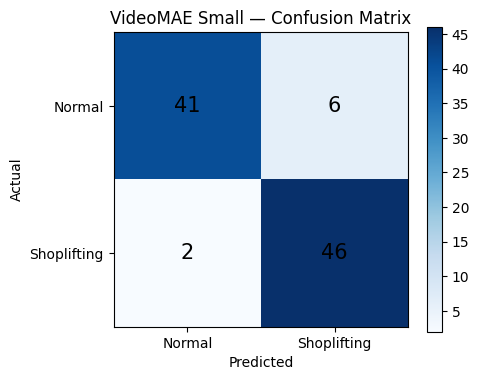


Saved metrics, predictions and confusion matrix.


In [9]:
# 8 — Final test evaluation
# Existing 95-video test has already been inspected in previous experiments.
# This comparison is internal, not a fresh external generalization estimate.
# Do not choose hyperparameters or epochs based on this result.

assert FINAL_PATH.is_file(), "Run fixed-epoch fine-tuning first."

checkpoint = torch.load(
    FINAL_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model"])
model.to(device)
model.eval()

all_true = []
all_pred = []
all_prob = []

with torch.inference_mode():
    for clips, labels in tqdm(
        test_loader, desc="Final Test"
    ):
        clips = clips.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(pixel_values=clips).logits

        probs = torch.softmax(
            logits.float(), dim=1
        ).cpu().numpy()

        all_true.extend(labels.tolist())
        all_pred.extend(probs.argmax(axis=1).tolist())
        all_prob.extend(probs[:, 1].tolist())

metrics = {
    "n_test": len(all_true),
    "accuracy": accuracy_score(all_true, all_pred),
    "precision_macro": precision_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "shoplifting_recall": recall_score(
        all_true, all_pred,
        pos_label=1, zero_division=0
    )
}

print("\nVideoMAE Small — Final Test Metrics")
print(json.dumps(metrics, indent=2))

print("\nClassification Report:")
print(classification_report(
    all_true, all_pred,
    labels=[0, 1],
    target_names=["Normal", "Shoplifting"],
    zero_division=0
))

cm = confusion_matrix(
    all_true, all_pred, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

predictions = test_rows[
    ["sha256", "relative_path", "label"]
].copy()

predictions["predicted"] = all_pred
predictions["shoplifting_probability"] = all_prob

predictions.to_csv(
    OUT / "final_test_predictions.csv",
    index=False
)

with open(OUT / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            fontsize=15
        )

ax.set_xticks([0, 1], ["Normal", "Shoplifting"])
ax.set_yticks([0, 1], ["Normal", "Shoplifting"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("VideoMAE Small — Confusion Matrix")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(
    OUT / "confusion_matrix.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

print("\nSaved metrics, predictions and confusion matrix.")